[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/04-machine-learning/notebooks/02-classification-and-metrics.ipynb)

# 04-02 · Classification and the metrics that matter

**Goal:** train a classifier on the breast-cancer dataset and understand every evaluation number: confusion matrix, accuracy, precision, recall, F1, the decision threshold, and ROC-AUC. Then see why accuracy can lie.

**Words:** **classification** — predicting a category. **positive class** — the class we are hunting for (here: malignant). **probability** — a number from 0 to 1 saying how sure the model is.

## Step 1 · Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_wine, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report,
                             roc_auc_score, RocCurveDisplay)

## Step 2 · Load the data and choose the positive class

In this dataset `0 = malignant` (cancer) and `1 = benign` (not cancer). We are hunting for cancer, so we flip the labels: `1 = malignant`. Then "positive" means "malignant", which makes precision and recall easier to talk about.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = (data.target == 0).astype(int)   # 1 = malignant (positive), 0 = benign
print(X.shape)
print("class counts:", y.value_counts().to_dict(), " -> 1 = malignant")
print("share malignant:", round(y.mean(), 3))

(569, 30)
class counts: {0: 357, 1: 212}  -> 1 = malignant
share malignant: 0.373


## Step 3 · Split with stratify

`stratify=y` keeps the same share of malignant cases (about 37%) in both training and test sets.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print("train malignant share:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

train malignant share: 0.373  test: 0.371


## Step 4 · Train logistic regression inside a pipeline

The 30 features have very different sizes (some around 0.05, some around 1000). We put a `StandardScaler` in front of the model inside a **pipeline**, so scaling is learned from the training data only. Concepts section 11 and 13 explain why.

In [4]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(X_train, y_train)
pred = clf.predict(X_test)
proba = clf.predict_proba(X_test)[:, 1]    # probability of class 1 (malignant)
print("first 8 predictions:   ", pred[:8])
print("first 8 probabilities: ", proba[:8].round(3))

first 8 predictions:    [1 0 1 0 0 0 0 0]
first 8 probabilities:  [0.999 0.004 1.    0.    0.035 0.004 0.    0.002]


## Step 5 · The confusion matrix, box by box

`confusion_matrix(y_true, y_pred)` returns a 2×2 grid. With labels ordered `[0, 1]`, the layout is:

```
               predicted 0   predicted 1
actual 0   [[     TN            FP     ],
actual 1    [     FN            TP     ]]
```

Careful: scikit-learn puts the negative class first, so TP is in the **bottom-right**. `.ravel()` flattens it into `tn, fp, fn, tp`.

[[89  1]
 [ 4 49]]
TP=49 (cancer, caught)   FN=4 (cancer, MISSED)
FP=1 (healthy, false alarm)   TN=89 (healthy, correctly cleared)


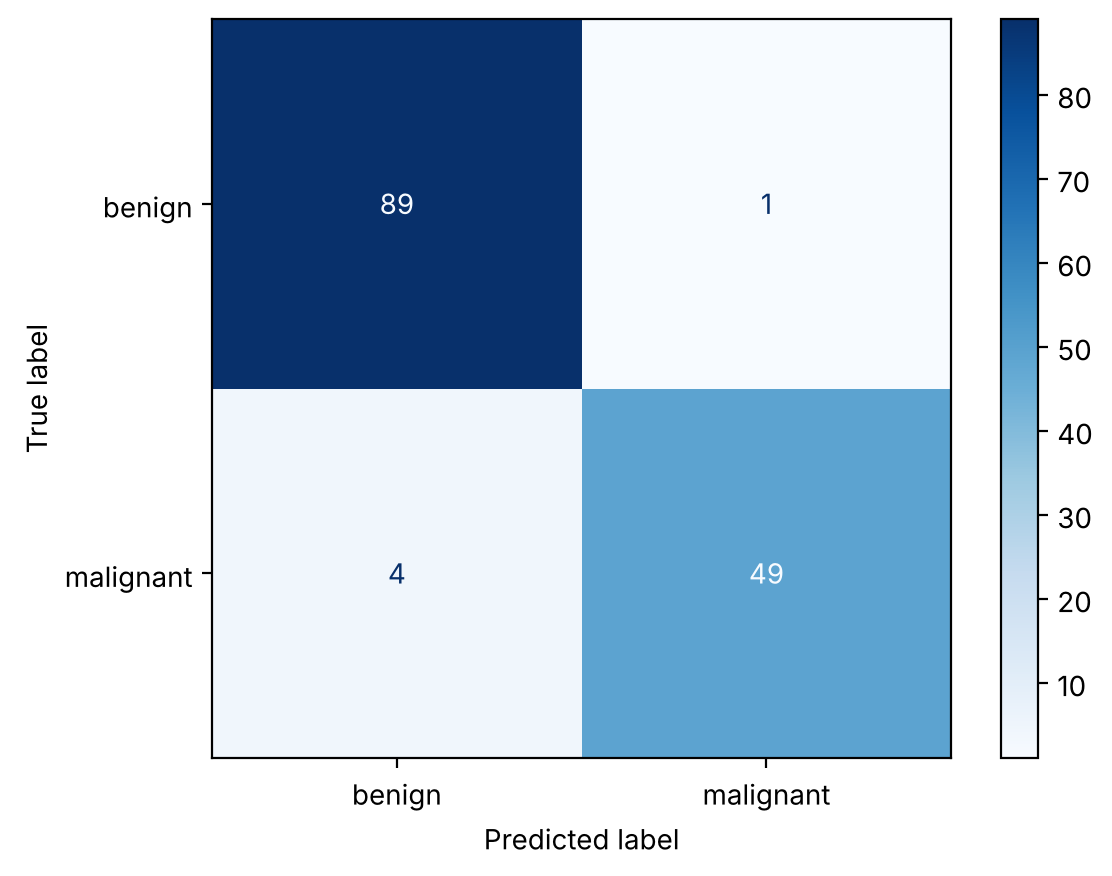

In [5]:
cm = confusion_matrix(y_test, pred)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"TP={tp} (cancer, caught)   FN={fn} (cancer, MISSED)")
print(f"FP={fp} (healthy, false alarm)   TN={tn} (healthy, correctly cleared)")
ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"]).plot(cmap="Blues")
plt.show()

## Step 6 · Every metric from the four boxes

We calculate each one by hand from `tp, fp, fn, tn`, then check against scikit-learn's functions.

In [6]:
accuracy  = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall    = tp / (tp + fn)
f1        = 2 * precision * recall / (precision + recall)

print(f"accuracy : by hand {accuracy:.3f}  sklearn {accuracy_score(y_test, pred):.3f}")
print(f"precision: by hand {precision:.3f}  sklearn {precision_score(y_test, pred):.3f}")
print(f"recall   : by hand {recall:.3f}  sklearn {recall_score(y_test, pred):.3f}")
print(f"f1       : by hand {f1:.3f}  sklearn {f1_score(y_test, pred):.3f}")

accuracy : by hand 0.965  sklearn 0.965
precision: by hand 0.980  sklearn 0.980
recall   : by hand 0.925  sklearn 0.925
f1       : by hand 0.951  sklearn 0.951


`classification_report` prints precision, recall and F1 for **each** class, plus averages. **support** = how many true examples of that class were in the test set. **macro avg** = plain average over classes; **weighted avg** = average weighted by support.

In [7]:
print(classification_report(y_test, pred, target_names=["benign", "malignant"]))

              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        90
   malignant       0.98      0.92      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143



## Step 7 · Moving the threshold

`predict()` uses a threshold of 0.5 on the probability. In cancer screening a missed cancer (FN) is far worse than a false alarm (FP), so a doctor might accept more false alarms to catch more cancers. Watch recall go up and precision go down as the threshold drops.

In [8]:
for threshold in [0.9, 0.7, 0.5, 0.3, 0.1]:
    p = (proba >= threshold).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    print(f"threshold {threshold:.1f}: TP={tp_:2d} FN={fn_:2d} FP={fp_:2d}  "
          f"precision={precision_score(y_test, p):.3f} recall={recall_score(y_test, p):.3f}")

threshold 0.9: TP=43 FN=10 FP= 0  precision=1.000 recall=0.811
threshold 0.7: TP=48 FN= 5 FP= 0  precision=1.000 recall=0.906
threshold 0.5: TP=49 FN= 4 FP= 1  precision=0.980 recall=0.925
threshold 0.3: TP=51 FN= 2 FP= 1  precision=0.981 recall=0.962
threshold 0.1: TP=52 FN= 1 FP= 6  precision=0.897 recall=0.981


## Step 8 · ROC curve and AUC

The **ROC curve** plots recall (true positive rate) against the false positive rate for every possible threshold. **AUC** (area under the curve) summarises it: 1.0 is perfect, 0.5 is a coin flip. AUC uses the probabilities, not the 0/1 predictions.

ROC-AUC: 0.9962


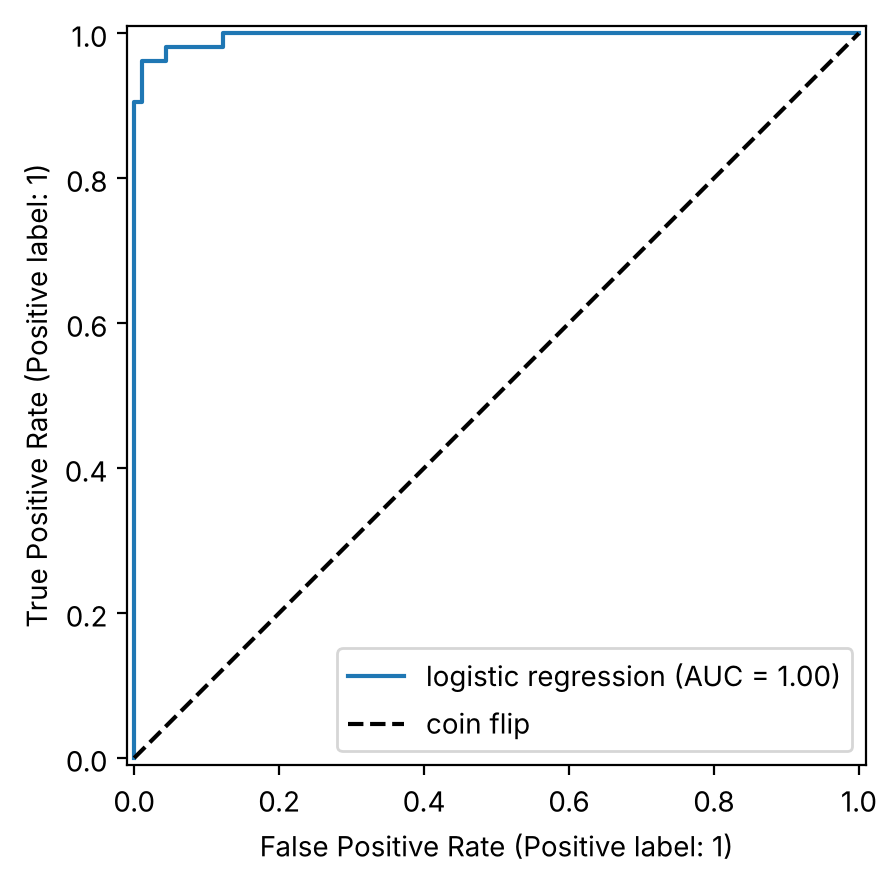

In [9]:
auc = roc_auc_score(y_test, proba)
print("ROC-AUC:", round(auc, 4))
RocCurveDisplay.from_predictions(y_test, proba, name="logistic regression")
plt.plot([0, 1], [0, 1], "k--", label="coin flip")
plt.legend(); plt.show()

## Step 9 · The accuracy trap (class imbalance)

We generate fake data where only **5%** of rows are positive (think: fraud). A "model" that always predicts "not fraud" gets about 95% accuracy — and catches zero fraud. Precision/recall reveal the truth.

`make_classification` builds a synthetic dataset; `weights=[0.95]` makes 95% of rows class 0.

In [10]:
Xi, yi = make_classification(n_samples=2000, n_features=10, weights=[0.95], random_state=0)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=0, stratify=yi)

lazy = DummyClassifier(strategy="most_frequent").fit(Xi_tr, yi_tr)
real = LogisticRegression(max_iter=1000).fit(Xi_tr, yi_tr)
for name, m in [("always 'no fraud'", lazy), ("logistic regression", real)]:
    p = m.predict(Xi_te)
    print(f"{name:20s} accuracy={accuracy_score(yi_te, p):.3f}  "
          f"recall={recall_score(yi_te, p, zero_division=0):.3f}  "
          f"precision={precision_score(yi_te, p, zero_division=0):.3f}")

always 'no fraud'    accuracy=0.947  recall=0.000  precision=0.000
logistic regression  accuracy=0.993  recall=0.875  precision=1.000


The lazy model's accuracy looks great but its recall is 0. **Lesson:** with imbalanced classes, always look at the confusion matrix, precision and recall.

## Step 10 · Multi-class classification (three wine types)

Everything works the same with more than two classes. The confusion matrix becomes 3×3: rows are the true class, columns the predicted class, and the diagonal holds the correct answers.

In [11]:
wine = load_wine()
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(wine.data, wine.target, test_size=0.3,
                                              random_state=1, stratify=wine.target)
wine_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xw_tr, yw_tr)
pw = wine_clf.predict(Xw_te)
print(confusion_matrix(yw_te, pw))
print(classification_report(yw_te, pw, target_names=wine.target_names))

[[18  0  0]
 [ 0 20  1]
 [ 0  0 15]]
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.95      0.98        21
     class_2       0.94      1.00      0.97        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



## Recap

- Confusion matrix → TP, FP, FN, TN → every other metric.
- **Precision**: of what I flagged, how much was right. **Recall**: of what was there, how much I found.
- The threshold trades precision against recall; choose it from the real cost of each mistake.
- AUC judges the probability scores across all thresholds.
- Accuracy alone lies when classes are imbalanced.

Use `excel/04-ml-metrics.xlsx` → *Confusion Matrix Calculator* to practise with your own numbers.